<a href="https://colab.research.google.com/github/Paul412399/PROIECT-PI/blob/main/PigEstimation2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q ultralytics yt-dlp

import os, shutil, glob
src = '/content/video1.mp4.mkv'
if os.path.exists('/content/drive/MyDrive/video1.mp4.mkv'):
    shutil.copy('/content/drive/MyDrive/video1.mp4.mkv', src)
else:
    !yt-dlp -f "bv*[height<=720]+ba/b[height<=720]" -o /content/video1.mp4 "https://www.youtube.com/watch?v=8tpbMI6hVFc"
    gasit = glob.glob('/content/video1*')
    print(gasit)
    if gasit:
        shutil.copy(gasit[0], src)
        shutil.copy(src, '/content/drive/MyDrive/video1.mp4.mkv')
print('video gasit:', os.path.exists(src))
print('model gasit:', os.path.exists('/content/drive/MyDrive/swine_runs/train_iarba3/weights/best.pt'))

Mounted at /content/drive
video gasit: True
model gasit: True


In [ ]:
import cv2, gc, pandas as pd
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/swine_runs/train_iarba3/weights/best.pt')

cap = cv2.VideoCapture(src)
fps = cap.get(cv2.CAP_PROP_FPS); W = int(cap.get(3)); H = int(cap.get(4))
cap.release()

out = cv2.VideoWriter('/content/rezultat_raw.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
rows = []
for i, r in enumerate(model.predict(src, stream=True, conf=0.25, verbose=False)):
    out.write(r.plot())
    if r.keypoints is not None and len(r.boxes) > 0:
        b = int(r.boxes.conf.argmax())
        k = r.keypoints.xy[b].cpu().numpy()
        c = r.keypoints.conf[b].cpu().numpy()
        row = {'frame': i}
        for j in range(15):
            row[f'x{j}'], row[f'y{j}'], row[f'c{j}'] = k[j][0], k[j][1], c[j]
        rows.append(row)
    if i % 200 == 0:
        gc.collect()
out.release()

pd.DataFrame(rows).to_csv('/content/drive/MyDrive/puncte_video1_v3.csv', index=False)
print(len(rows), 'cadre cu porc din', i + 1)
!ffmpeg -y -loglevel error -i /content/rezultat_raw.mp4 -vcodec libx264 -pix_fmt yuv420p /content/drive/MyDrive/rezultat_v3.mp4
print('gata: rezultat_v3.mp4 e in Drive')

from google.colab import files
files.download('/content/drive/MyDrive/rezultat_v3.mp4')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
1705 cadre cu porc din 1705
gata: rezultat_v3.mp4 e in Drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
lungime corp ~ 674 px


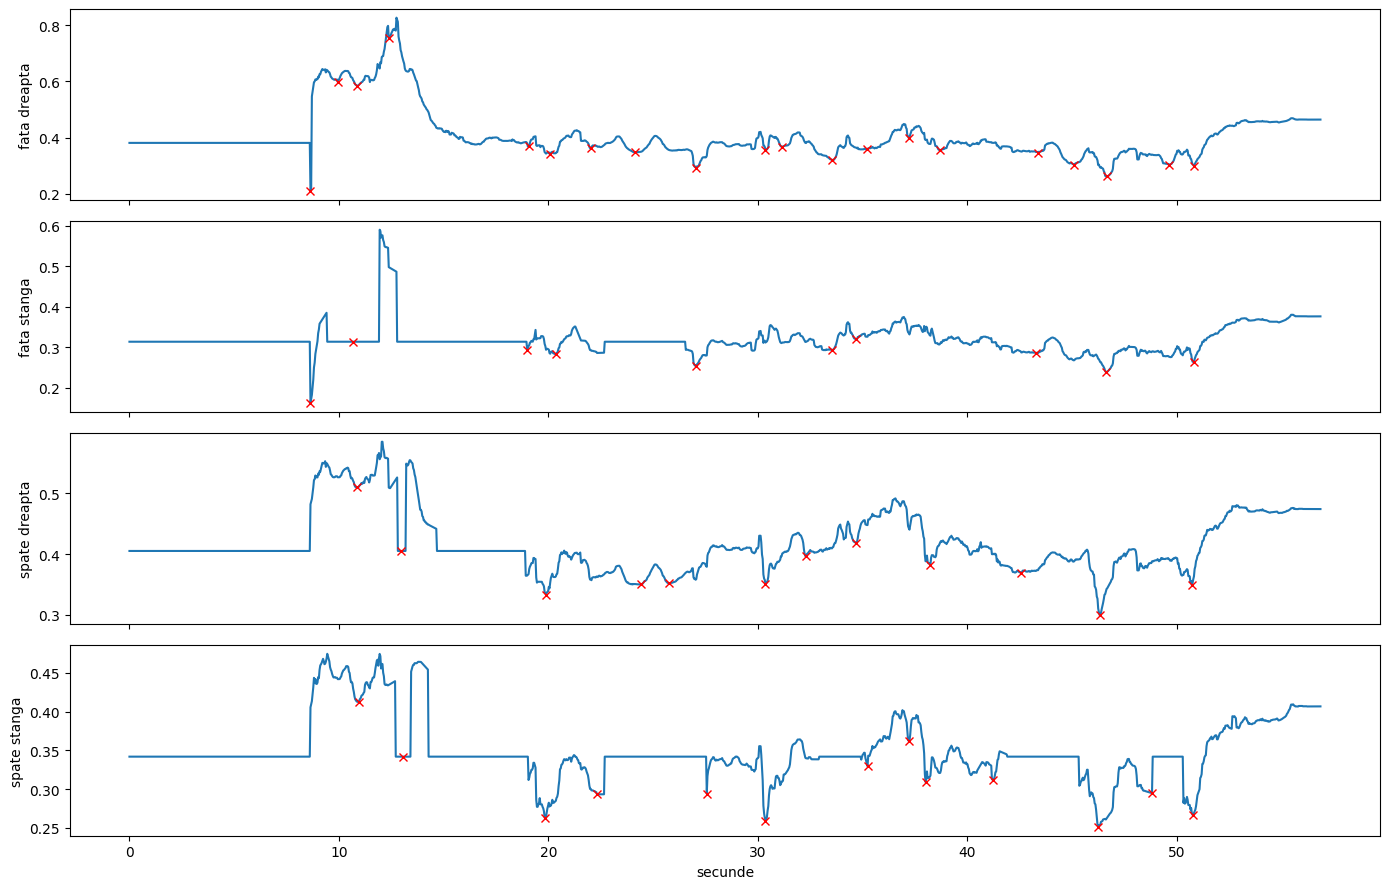

          picior  pasi  interval_mediu_s  variatie_ritm_%  amplitudine
0   fata dreapta    20              2.22            63.12         0.06
1    fata stanga    10              4.69            58.65         0.07
2  spate dreapta    12              3.62            42.05         0.05
3   spate stanga    13              3.32            50.91         0.05
asimetrie amplitudine fata : 15.4 %
asimetrie amplitudine spate: 0.0 %
DIAGNOSTIC BIOMECANIC AUTOMAT
Asimetrie fata: 15.4%
Asimetrie spate: 0.0%
Variatie maxima de ritm: 63.1%
Verdict: Schiop / Anomalie de mers detectata


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.signal import find_peaks
from google.colab import drive
drive.mount('/content/drive')

FPS = 29.97
df = pd.read_csv('/content/drive/MyDrive/puncte_video1_v3.csv').set_index('frame')
df = df.reindex(range(int(df.index.max()) + 1))

def serie(j, prag=0.5):
    x, y, c = df[f'x{j}'].copy(), df[f'y{j}'].copy(), df[f'c{j}']
    x[c < prag] = np.nan
    y[c < prag] = np.nan
    x = x.interpolate(limit=10, limit_area='inside')
    y = y.interpolate(limit=10, limit_area='inside')
    return (x.rolling(5, center=True, min_periods=1).median(),
            y.rolling(5, center=True, min_periods=1).median())

P = {j: serie(j) for j in range(15)}
nx, ny = P[0]; hx, hy = P[6]
L = np.nanmedian(np.hypot(nx - hx, ny - hy))
print('lungime corp ~', round(L), 'px')

nume = {7: 'fata dreapta', 11: 'fata stanga', 8: 'spate dreapta', 14: 'spate stanga'}
rez = []
fig, ax = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for a, (j, n) in zip(ax, nume.items()):
    _, ty = P[j]
    h = (ty - hy) / L
    v = h.interpolate(limit=10, limit_area='inside').fillna(h.median()).values
    pk, pr = find_peaks(-v, prominence=0.03, distance=int(0.3 * FPS))
    t = pk / FPS
    interv = np.diff(t)
    rez.append({'picior': n, 'pasi': len(pk),
                'interval_mediu_s': np.mean(interv) if len(interv) else np.nan,
                'variatie_ritm_%': 100 * np.std(interv) / np.mean(interv) if len(interv) > 1 else np.nan,
                'amplitudine': np.median(pr['prominences']) if len(pk) else np.nan})
    a.plot(np.arange(len(v)) / FPS, v); a.plot(t, v[pk], 'rx'); a.set_ylabel(n)
ax[-1].set_xlabel('secunde'); plt.tight_layout()
plt.savefig('/content/drive/MyDrive/mers_picioare.png', dpi=120); plt.show()

tab = pd.DataFrame(rez).round(2)
print(tab)
asim = lambda a, b: 100 * abs(a - b) / ((a + b) / 2)
print('asimetrie amplitudine fata :', round(asim(tab.amplitudine[0], tab.amplitudine[1]), 1), '%')
print('asimetrie amplitudine spate:', round(asim(tab.amplitudine[2], tab.amplitudine[3]), 1), '%')

asimetrie_fata = asim(tab.amplitudine[0], tab.amplitudine[1])
asimetrie_spate = asim(tab.amplitudine[2], tab.amplitudine[3])
var_ritm_max = tab['variatie_ritm_%'].max()

print("DIAGNOSTIC BIOMECANIC AUTOMAT")
print(f"Asimetrie fata: {asimetrie_fata:.1f}%")
print(f"Asimetrie spate: {asimetrie_spate:.1f}%")
print(f"Variatie maxima de ritm: {var_ritm_max:.1f}%")

if asimetrie_fata > 10 or asimetrie_spate > 10 or var_ritm_max > 35:
    print("Verdict: Schiop / Anomalie de mers detectata")
else:
    print("Verdict: Mers simetric si stabil")

In [ ]:
import cv2
import pandas as pd
import numpy as np
from scipy.signal import find_peaks

FPS = 29.97
df = pd.read_csv('/content/drive/MyDrive/puncte_video1_v3.csv').set_index('frame')
df = df.reindex(range(int(df.index.max()) + 1))

def serie(j, prag=0.5):
    x, y, c = df[f'x{j}'].copy(), df[f'y{j}'].copy(), df[f'c{j}']
    x[c < prag] = np.nan
    y[c < prag] = np.nan
    x = x.interpolate(limit=10, limit_area='inside')
    y = y.interpolate(limit=10, limit_area='inside')
    return (x.rolling(5, center=True, min_periods=1).median(),
            y.rolling(5, center=True, min_periods=1).median())

P = {j: serie(j) for j in range(15)}
nx, ny = P[0]; hx, hy = P[6]
L = np.nanmedian(np.hypot(nx - hx, ny - hy))

nume = {7: 'fata dreapta', 11: 'fata stanga', 8: 'spate dreapta', 14: 'spate stanga'}
rez = []
for j, n in nume.items():
    _, ty = P[j]
    h = (ty - hy) / L
    v = h.interpolate(limit=10, limit_area='inside').fillna(h.median()).values
    pk, pr = find_peaks(-v, prominence=0.03, distance=int(0.3 * FPS))
    t = pk / FPS
    interv = np.diff(t)
    rez.append({'picior': n, 'pasi': len(pk),
                'interval_mediu_s': np.mean(interv) if len(interv) else np.nan,
                'variatie_ritm_%': 100 * np.std(interv) / np.mean(interv) if len(interv) > 1 else np.nan,
                'amplitudine': np.median(pr['prominences']) if len(pk) else np.nan})

tab = pd.DataFrame(rez).round(2)
asim = lambda a, b: 100 * abs(a - b) / ((a + b) / 2)

asimetrie_fata = asim(tab.amplitudine[0], tab.amplitudine[1])
asimetrie_spate = asim(tab.amplitudine[2], tab.amplitudine[3])
var_ritm_max = tab['variatie_ritm_%'].max()

if asimetrie_fata > 10 or asimetrie_spate > 10 or var_ritm_max > 35:
    text = "Verdict: Schiop / Anomalie"
    culoare = (0, 0, 255)
else:
    text = "Verdict: Mers simetric si stabil"
    culoare = (0, 255, 0)

video_sursa = '/content/drive/MyDrive/rezultat_v3.mp4'

cap = cv2.VideoCapture(video_sursa)
fps = cap.get(cv2.CAP_PROP_FPS)
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

out = cv2.VideoWriter('/content/drive/MyDrive/rezultat_final_schiop.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    cv2.putText(frame, text, (40, 70), cv2.FONT_HERSHEY_SIMPLEX, 1.0, culoare, 3, cv2.LINE_AA)
    out.write(frame)

cap.release()
out.release()
print("Gata: rezultat_final_schiop.mp4 a fost salvat in Drive cu tot cu articulații și diagnostic!")
print(text)

Gata: rezultat_final_schiop.mp4 a fost salvat in Drive cu tot cu articulații și diagnostic!
Verdict: Schiop / Anomalie


In [ ]:
from google.colab import files, drive
drive.mount('/content/drive')
!pip install -q ultralytics
import os, shutil

print('model gasit:', os.path.exists('/content/drive/MyDrive/swine_runs/train_iarba3/weights/best.pt'))

up = files.upload()
shutil.copy('/content/porc_mersnormal.mp4', '/content/drive/MyDrive/porc_mersnormal.mp4')
print('video gasit:', os.path.exists('/content/porc_mersnormal.mp4'))

Mounted at /content/drive
model gasit: True


Saving porc_mersnormal.mp4 to porc_mersnormal.mp4
video gasit: True


In [ ]:
import cv2, os
os.makedirs('/content/cadre_normal', exist_ok=True)
cap = cv2.VideoCapture('/content/porc_mersnormal.mp4')
i = 0
while True:
    ok, fr = cap.read()
    if not ok: break
    if i % 10 == 0 and i < 190:
        cv2.imwrite(f'/content/cadre_normal/n{i:05d}.jpg', fr[10:1070, 230:1670])
    i += 1
cap.release()
print(len(os.listdir('/content/cadre_normal')), 'cadre')
!zip -rq /content/cadre_normal.zip /content/cadre_normal
!cp /content/cadre_normal.zip /content/drive/MyDrive/

19 cadre


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="iPF1j3oWPcRlo4FpYHIY")
project = rf.workspace("mihaela-moisa").project("pig-iarba")
version = project.version(5)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 26.7 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to pig-iarba-5 in yolov8:: 100%|██████████| 137/137 [00:00<00:00, 5219.45it/s]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q ultralytics roboflow

In [ ]:
from ultralytics import YOLO
from roboflow import Roboflow

model = YOLO('/content/drive/MyDrive/swine_runs/train_iarba3/weights/best.pt')

model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=100,
    imgsz=640,
    batch=8,
    patience=30,
    project='/content/drive/MyDrive/swine_runs',
    name='train_iarba5'
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pig-iarba-5/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/swine_runs/train_iarba3/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_

ultralytics.utils.metrics.PoseMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7da0a99f9470>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(P)', 'F1-Confidence(P)', 'Precision-Confidence(P)', 'Recall-Confidence(P)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    

In [ ]:
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/swine_runs/train_iarba5/weights/best.pt')

results = model.track(
    source='/content/drive/MyDrive/porc_mersnormal.mp4',
    conf=0.4,
    tracker='bytetrack.yaml',
    save=True,
    show=False,
    project='/content/drive/MyDrive',
    name='rezultate_porci'
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/227) /content/drive/MyDrive/porc_mersnormal.mp4: 384x640 1 pig, 13.9ms
video 1/1 (frame 2/227) /content/drive/MyDrive/porc_mersnormal.mp4: 384x640 1 pig, 17.1ms
video 1/1 (frame 3/227) /content/drive/MyDrive/porc_mersnormal.mp4: 384x640 1 pig, 23.0ms
video 1/1 (frame 4/227) /content/drive/MyDrive/porc_mersnormal.mp4: 384x640 1 pig, 16.6ms
video 1/1 (frame 5/227) /content/drive/MyDrive/porc_mersnormal.mp4: 384x640 1 pig, 15.9ms
video 1/1

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q ultralytics
import os
print('model:', os.path.exists('/content/drive/MyDrive/swine_runs/train_iarba5/weights/best.pt'))
print('video schiopat:', os.path.exists('/content/drive/MyDrive/video1.mp4.mkv'))
print('video normal:', os.path.exists('/content/drive/MyDrive/porc_mersnormal.mp4'))

Mounted at /content/drive
model: True
video schiopat: True
video normal: True


In [ ]:
import cv2, gc, subprocess, numpy as np, pandas as pd
from scipy.signal import find_peaks
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/swine_runs/train_iarba5/weights/best.pt')

MIN_PASI = 6
PRAG_RITM = 35
PRAG_PASI = 30

PARTI = {
  'dreapta': {'puncte': [2,3,4,5,7,8],      'copita_fata': 7,  'copita_spate': 8},
  'stanga' : {'puncte': [9,10,11,12,13,14], 'copita_fata': 11, 'copita_spate': 14},
}

def verdict(df, fps, prag=0.4):
    df = df.set_index('frame')
    df = df.reindex(range(int(df.index.max()) + 1))

    def serie(j):
        x, y, c = df[f'x{j}'].copy(), df[f'y{j}'].copy(), df[f'c{j}']
        x[c < prag] = np.nan; y[c < prag] = np.nan
        x = x.interpolate(limit=10, limit_area='inside')
        y = y.interpolate(limit=10, limit_area='inside')
        return (x.rolling(5, center=True, min_periods=1).median(),
                y.rolling(5, center=True, min_periods=1).median())

    inc = {p: df[[f'c{j}' for j in d['puncte']]].mean().mean() for p, d in PARTI.items()}
    parte = max(inc, key=inc.get); d = PARTI[parte]
    P = {j: serie(j) for j in [0, 6, d['copita_fata'], d['copita_spate']]}
    nx, ny = P[0]; hx, hy = P[6]
    L = np.nanmedian(np.hypot(nx - hx, ny - hy))

    pasi, var = {}, {}
    for nume in ['copita_fata', 'copita_spate']:
        _, toe_y = P[d[nume]]
        h = (toe_y - hy) / L
        v = h.interpolate(limit=10, limit_area='inside').fillna(h.median()).values
        pk, _ = find_peaks(-v, prominence=0.03, distance=max(2, int(0.3 * fps)))
        iv = np.diff(pk / fps)
        pasi[nume] = len(pk)
        var[nume] = 100 * np.std(iv) / np.mean(iv) if len(iv) > 1 else np.nan

    pf, ps = pasi['copita_fata'], pasi['copita_spate']
    detalii = (f"parte {parte} | pasi fata {pf}, spate {ps} | "
               f"variatie ritm {var['copita_fata']:.0f}% / {var['copita_spate']:.0f}%")

    if min(pf, ps) < MIN_PASI:
        return 'Date insuficiente (prea putini pasi)', (0, 255, 255), detalii
    if np.nanmax(list(var.values())) > PRAG_RITM:
        return 'Indicator: mers neregulat (posibil schiopat)', (0, 0, 255), detalii
    return 'Indicator: mers regulat', (0, 255, 0), detalii


def proceseaza(video, iesire, crop=None, stride=1):
    cap = cv2.VideoCapture(video)
    fps = cap.get(cv2.CAP_PROP_FPS) / stride
    rows, i, n, out = [], 0, 0, None
    while True:
        ok, fr = cap.read()
        if not ok: break
        if i % stride == 0:
            if crop:
                x0, y0, x1, y1 = crop
                fr = fr[y0:y1, x0:x1]
            r = model.predict(fr, conf=0.25, verbose=False)[0]
            img = r.plot()
            if out is None:
                H, W = img.shape[:2]
                out = cv2.VideoWriter('/content/tmp_raw.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
            out.write(img)
            if r.keypoints is not None and len(r.boxes) > 0:
                b = int(r.boxes.conf.argmax())
                k = r.keypoints.xy[b].cpu().numpy(); c = r.keypoints.conf[b].cpu().numpy()
                row = {'frame': n}
                for j in range(15):
                    row[f'x{j}'], row[f'y{j}'], row[f'c{j}'] = k[j][0], k[j][1], c[j]
                rows.append(row)
            n += 1
        i += 1
        if i % 200 == 0: gc.collect()
    cap.release(); out.release()
    print(len(rows), 'cadre cu porc din', n)

    if len(rows) < 10:
        text, culoare, detalii = 'Porc nedetectat', (0, 255, 255), ''
    else:
        df = pd.DataFrame(rows)
        df.to_csv(iesire.replace('.mp4', '_puncte.csv'), index=False)
        text, culoare, detalii = verdict(df, fps)
    print(text); print(detalii)

    cap = cv2.VideoCapture('/content/tmp_raw.mp4')
    out2 = cv2.VideoWriter('/content/tmp_final.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
    s = W / 1280
    while True:
        ok, fr = cap.read()
        if not ok: break
        h_banda = int(115 * s)
        fr[:h_banda] = (fr[:h_banda] * 0.35).astype('uint8')
        cv2.putText(fr, text, (int(30*s), int(55*s)), cv2.FONT_HERSHEY_SIMPLEX, 1.0*s, culoare, max(2, int(3*s)), cv2.LINE_AA)
        cv2.putText(fr, detalii, (int(30*s), int(95*s)), cv2.FONT_HERSHEY_SIMPLEX, 0.6*s, (255, 255, 255), max(1, int(2*s)), cv2.LINE_AA)
        out2.write(fr)
    cap.release(); out2.release()
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', '/content/tmp_final.mp4',
                    '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', iesire])
    print('Gata:', iesire)

parte folosita: stanga {'dreapta': np.float64(0.54), 'stanga': np.float64(0.94)}
lungime corp (px): 410
copita_fata: 4 pasi | momente (s): [       1.87         3.2        4.77         6.7] | intervale (s): [       1.33        1.57        1.93] | variatie 15% | cadre cu incredere mica: 0%
copita_spate: 6 pasi | momente (s): [        0.3         1.3         2.1           3         4.7         6.6] | intervale (s): [          1         0.8         0.9         1.7         1.9] | variatie 36% | cadre cu incredere mica: 0%


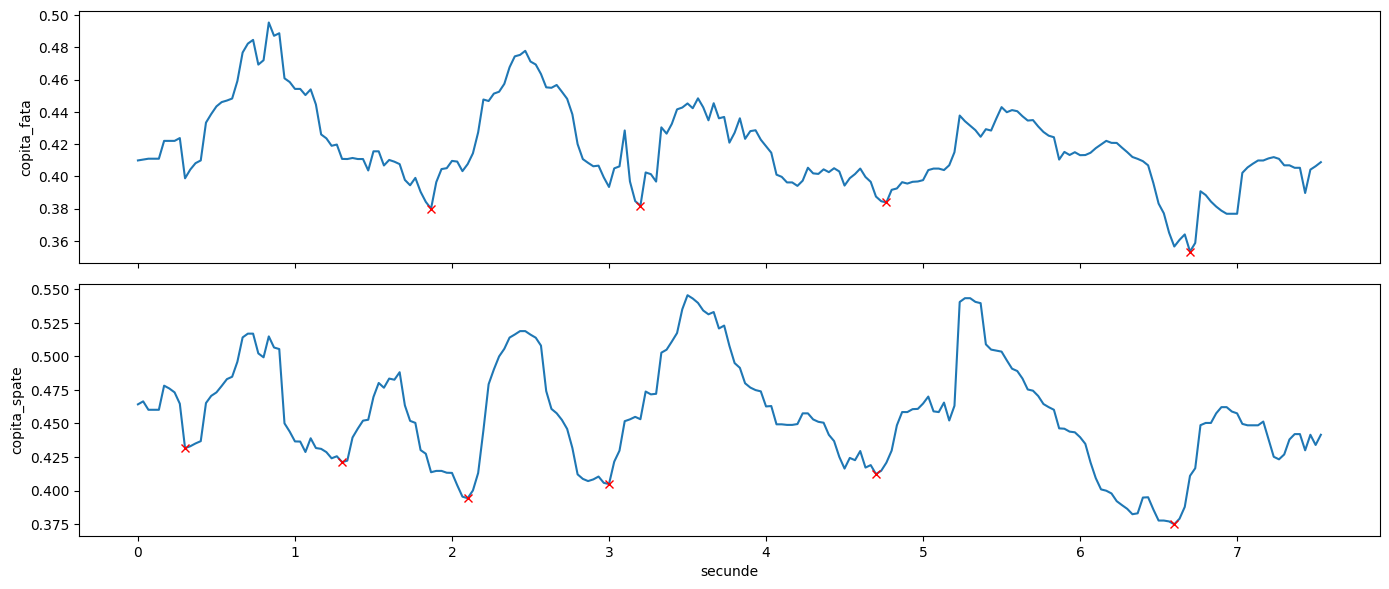

ritm neregulat (peste 35 %): True
numar de pasi diferit (peste 30 %): True


In [ ]:
import matplotlib.pyplot as plt

def diagnostic(csv, fps, prag=0.4):
    df = pd.read_csv(csv).set_index('frame')
    df = df.reindex(range(int(df.index.max()) + 1))

    def serie(j):
        x, y, c = df[f'x{j}'].copy(), df[f'y{j}'].copy(), df[f'c{j}']
        x[c < prag] = np.nan; y[c < prag] = np.nan
        x = x.interpolate(limit=10, limit_area='inside')
        y = y.interpolate(limit=10, limit_area='inside')
        return (x.rolling(5, center=True, min_periods=1).median(),
                y.rolling(5, center=True, min_periods=1).median())

    inc = {p: df[[f'c{j}' for j in d['puncte']]].mean().mean() for p, d in PARTI.items()}
    parte = max(inc, key=inc.get); d = PARTI[parte]
    print('parte folosita:', parte, {k: round(v, 2) for k, v in inc.items()})

    P = {j: serie(j) for j in [0, 6, d['copita_fata'], d['copita_spate']]}
    nx, ny = P[0]; hx, hy = P[6]
    L = np.nanmedian(np.hypot(nx - hx, ny - hy))
    print('lungime corp (px):', round(L))

    fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    pasi, var = {}, {}
    for a, nume in zip(ax, ['copita_fata', 'copita_spate']):
        j = d[nume]
        gol = df[f'c{j}'].lt(prag).mean() * 100
        _, toe_y = P[j]
        h = (toe_y - hy) / L
        v = h.interpolate(limit=10, limit_area='inside').fillna(h.median()).values
        pk, _ = find_peaks(-v, prominence=0.03, distance=max(2, int(0.3 * fps)))
        iv = np.diff(pk / fps)
        pasi[nume] = len(pk)
        var[nume] = 100 * np.std(iv) / np.mean(iv) if len(iv) > 1 else np.nan
        print(f'{nume}: {len(pk)} pasi | momente (s): {np.round(pk / fps, 2)} | intervale (s): {np.round(iv, 2)} '
              f'| variatie {var[nume]:.0f}% | cadre cu incredere mica: {gol:.0f}%')
        a.plot(np.arange(len(v)) / fps, v); a.plot(pk / fps, v[pk], 'rx'); a.set_ylabel(nume)
    ax[-1].set_xlabel('secunde'); plt.tight_layout(); plt.show()

    pf, ps = pasi['copita_fata'], pasi['copita_spate']
    print('ritm neregulat (peste', PRAG_RITM, '%):', bool(np.nanmax(list(var.values())) > PRAG_RITM))
    print('numar de pasi diferit (peste', PRAG_PASI, '%):', bool(100 * abs(pf - ps) / max(pf, ps) > PRAG_PASI))

diagnostic('/content/drive/MyDrive/rezultat_final_normal_puncte.csv', 30.0)

In [ ]:
proceseaza('/content/drive/MyDrive/porc_mersnormal.mp4',
           '/content/drive/MyDrive/rezultat_final_normal.mp4', crop=(230, 10, 1670, 1070))
from google.colab import files
files.download('/content/drive/MyDrive/rezultat_final_normal.mp4')

227 cadre cu porc din 227
Date insuficiente (prea putini pasi)
parte stanga | pasi fata 4, spate 6 | variatie ritm 15% / 36%
Gata: /content/drive/MyDrive/rezultat_final_normal.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
proceseaza('/content/drive/MyDrive/video1.mp4.mkv',
           '/content/drive/MyDrive/rezultat_final_schiop.mp4', stride=2)
files.download('/content/drive/MyDrive/rezultat_final_schiop.mp4')

853 cadre cu porc din 853
Indicator: mers neregulat (posibil schiopat)
parte dreapta | pasi fata 17, spate 10 | variatie ritm 65% / 49%
Gata: /content/drive/MyDrive/rezultat_final_schiop.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>